# PMU Hierarchical Classification Model Training

This notebook trains hierarchical binary classifiers for PMU (Phasor Measurement Unit) data classification using XGBoost and Random Forest models.

## Overview
- Trains binary classifiers for each class (secondary) and sub-class (tertiary) label
- Handles class imbalance using Gaussian Mixture Model (GMM) for synthetic sample generation
- Performs hyperparameter tuning using RandomizedSearchCV
- Evaluates models using hierarchical precision, recall, and F-score metrics
- Saves trained models as pickle files for later use

## Table of Content
1. Import Required Libraries
2. Configuration and Global Variables
3. Load Input Data and Dictionaries
4. Input Data Exploration and Analysis
5. Utility Functions
    5.1 Class Rebalancing Function

    5.2. Model Training Function

    5.3. Prediction Functions

    5.4. Validation Function

6. Model Training Pipeline
7. Main Function
    7.1. Pipeline Functions (`compute_secondary_metrics`, `main`)

    7.2. Configure & Run the Pipeline

8. Model Validation and Testing
9. Results Analysis and Visualization
10. Model Inspection and Analysis




## 1. Import Required Libraries

In [1]:
# Basic libraries
import pandas as pd
import numpy as np
import os

# Plotting
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats

# Classification Models
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb

# Mixture Models
from sklearn.mixture import GaussianMixture

# Model Tuning
from sklearn.model_selection import train_test_split, RandomizedSearchCV, KFold

# Model Scoring
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score

# Pickling
import pickle

# Data formats
import json

# Display settings
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', None)

# For better plots in notebook
%matplotlib inline

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
import warnings
from sklearn.exceptions import FitFailedWarning

# Hide the "least populated class" warning from model_selection._split
warnings.filterwarnings(
    "ignore",
    message=".*least populated class.*",
    category=UserWarning,
)

# Hide the long FitFailedWarning dumps from GridSearchCV / cross_val
warnings.filterwarnings("ignore", category=FitFailedWarning)

# Hide the "test scores are non-finite" message from _search
warnings.filterwarnings(
    "ignore",
    message="One or more of the test scores are non-finite.*",
    category=UserWarning,
)


## 2. Configuration and Global Variables

In [2]:
# File paths
INPUT_DATA_FILE = 'Inputs/pmu_transmission_features.csv'
SEC_TO_TERT_DICT_FILE = 'Inputs/sec_to_tert_dict_transmission.json'

# Directory paths
CLASSIFIER_PATH = 'Classifiers'
OUTPUT_PATH = 'Outputs'

# Model configuration
SAVE_PREFIX = 'XGB'  # Prefix for saved model files
N_ESTIMATORS = 1000  # Number of trees in the forest
MAX_DEPTH = 8        # Maximum depth of trees
RANDOM_STATE = 42    # For reproducibility

# Training configuration
flag_train_function = 1  # Set to 1 to train models, 0 to skip training

# Primary group labels
group_labels = ['Events', 'State', 'Equipment', 'Conditions', 'Phase']

# Create necessary directories
os.makedirs(CLASSIFIER_PATH, exist_ok=True)
os.makedirs(OUTPUT_PATH, exist_ok=True)

print(f"Configuration loaded:")
print(f"- Model prefix: {SAVE_PREFIX}")
print(f"- Training enabled: {bool(flag_train_function)}")
print(f"- Group labels: {group_labels}")

Configuration loaded:
- Model prefix: XGB
- Training enabled: True
- Group labels: ['Events', 'State', 'Equipment', 'Conditions', 'Phase']


## 3. Load Input Data and Dictionaries

In [3]:
# Load the main dataset
try:
    df = pd.read_csv(INPUT_DATA_FILE)
    print(f"Successfully loaded data from {INPUT_DATA_FILE}")
    print(f"Shape: {df.shape}")
    #print(f"\nColumns: {list(df.columns[:29])}...")  # Show first 10 columns
    print(f"\nFirst few rows:")
    display(df.head())
except FileNotFoundError:
    print(f"Error: Could not find {INPUT_DATA_FILE}")
    print("Please ensure the file is in the correct location.")

Successfully loaded data from Inputs/pmu_transmission_features.csv
Shape: (28204, 28)

First few rows:


,sigid,primary,secondary,tertiary,P001.df_mean,P001.df_std,P001.df_skew,P001.df_kurtosis,P001.f_mean,P001.f_std,P001.f_skew,P001.f_kurtosis,P001.ip_a_mean,P001.ip_a_std,P001.ip_a_skew,P001.ip_a_kurtosis,P001.ip_m_mean,P001.ip_m_std,P001.ip_m_skew,P001.ip_m_kurtosis,P001.vp_a_mean,P001.vp_a_std,P001.vp_a_skew,P001.vp_a_kurtosis,P001.vp_m_mean,P001.vp_m_std,P001.vp_m_skew,P001.vp_m_kurtosis
0,974,Equipment,Substation,Transmission,-9.780000e-17,1.000069,1.636972,815.653017,5.040000e-13,1.000069,-0.336977,-0.925765,2.800000e-16,1.000069,0.027336,-1.189300,-2.400000e-15,1.000069,0.211944,1.337818,1.210000e-15,1.000069,0.025759,-1.186279,1.410000e-14,1.000069,-24.240373,1122.540917
1,974,State,Change-State,Trip,-9.780000e-17,1.000069,1.636972,815.653017,5.040000e-13,1.000069,-0.336977,-0.925765,2.800000e-16,1.000069,0.027336,-1.189300,-2.400000e-15,1.000069,0.211944,1.337818,1.210000e-15,1.000069,0.025759,-1.186279,1.410000e-14,1.000069,-24.240373,1122.540917
2,975,Equipment,Overhead-Equipment,Conductor,4.430000e-17,1.000069,2.290180,206.810139,-2.060000e-13,1.000069,-0.961512,0.551813,9.070000e-17,1.000069,0.193661,-1.328263,1.270000e-14,1.000069,19.315180,605.768682,1.440000e-15,1.000069,0.194046,-1.328212,2.610000e-14,1.000069,-28.084094,1014.696433
3,975,State,Change-State,Trip,4.430000e-17,1.000069,2.290180,206.810139,-2.060000e-13,1.000069,-0.961512,0.551813,9.070000e-17,1.000069,0.193661,-1.328263,1.270000e-14,1.000069,19.315180,605.768682,1.440000e-15,1.000069,0.194046,-1.328212,2.610000e-14,1.000069,-28.084094,1014.696433
4,976,Equipment,Overhead-Equipment,Conductor,3.730000e-18,1.000069,0.821341,48.849595,-3.640000e-14,1.000069,-0.793079,-0.076992,5.150000e-16,1.000069,0.359388,-0.762278,-1.150000e-15,1.000069,0.771972,8.043328,1.220000e-15,1.000069,0.341874,-0.788582,1.740000e-13,1.000069,-18.540243,729.983718


In [53]:
import pandas as pd
import json

# Load the secondary to tertiary mapping dictionary
try:
    sec_to_tert_dict = json.load(open(SEC_TO_TERT_DICT_FILE))
    print(f"✅ Successfully loaded mapping dictionary from {SEC_TO_TERT_DICT_FILE}")
    print(f"Number of secondary labels: {len(sec_to_tert_dict)}")

    # Create a table for display
    table_data = []
    for i, (sec, tert_list) in enumerate(sec_to_tert_dict.items()):
        if i < 27:  # Limit output to first 26 entries
            table_data.append({
                "Secondary Label": sec,
                "Example Tertiary Labels": tert_list[:10]  
            })

    df_preview = pd.DataFrame(table_data)
    pd.set_option('display.max_colwidth', None)
    display(df_preview)  # Works in Jupyter, IPython, etc.

except FileNotFoundError:
    print(f"❌ Error: Could not find {SEC_TO_TERT_DICT_FILE}")
    print("Please ensure the file is in the correct location.")

✅ Successfully loaded mapping dictionary from Inputs/sec_to_tert_dict_transmission.json
Number of secondary labels: 26


,Secondary Label,Example Tertiary Labels
0,System-Event-Condition,"[Frequency-Deviation, Oscillation, Nonspecific-System-Event-Condition]"
1,External,"[Lightning-Strike, Nonspecific-External]"
2,Equipment-Failure,"[Nonspecific-Equipment-Failure, Transformer-Failure]"
3,Fault,[Nonspecific-Fault]
4,Construction-&-Maintenance,"[Maintenance, Accident, Nonspecific-Construction-&-Maintenance]"
5,Switching-Event,[Nonspecific-Switching-Event]
6,Vegetation,[Tree]
7,Other,[Fire]
8,Defect-or-Deterioration,[Contamination]
9,Wildlife,[Nonspecific-Wildlife]


## 4. Input Data Exploration and Analysis

Data Summary:


,Metric,Value
0,Total samples,28204



Primary label distribution:


,Primary Label,Count
0,State,11973
1,Events,7513
2,Equipment,6124
3,Conditions,1579
4,Phase,1015


,Metric,Value
0,Unique secondary labels,26


,Metric,Value
0,Unique tertiary labels,47



Missing values per *feature*:


,Missing Values,% Missing
P001.ip_a_kurtosis,162,0.57
P001.ip_a_skew,115,0.41
P001.ip_a_std,113,0.40
P001.ip_a_mean,109,0.39
P001.df_mean,106,0.38
P001.df_std,106,0.38
P001.df_skew,106,0.38
P001.df_kurtosis,106,0.38
P001.ip_m_mean,88,0.31
P001.ip_m_std,88,0.31


C:\Users\gandaramende1\AppData\Local\Temp\ipykernel_2196\1053424533.py:17: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap('viridis')  # nice, modern gradient


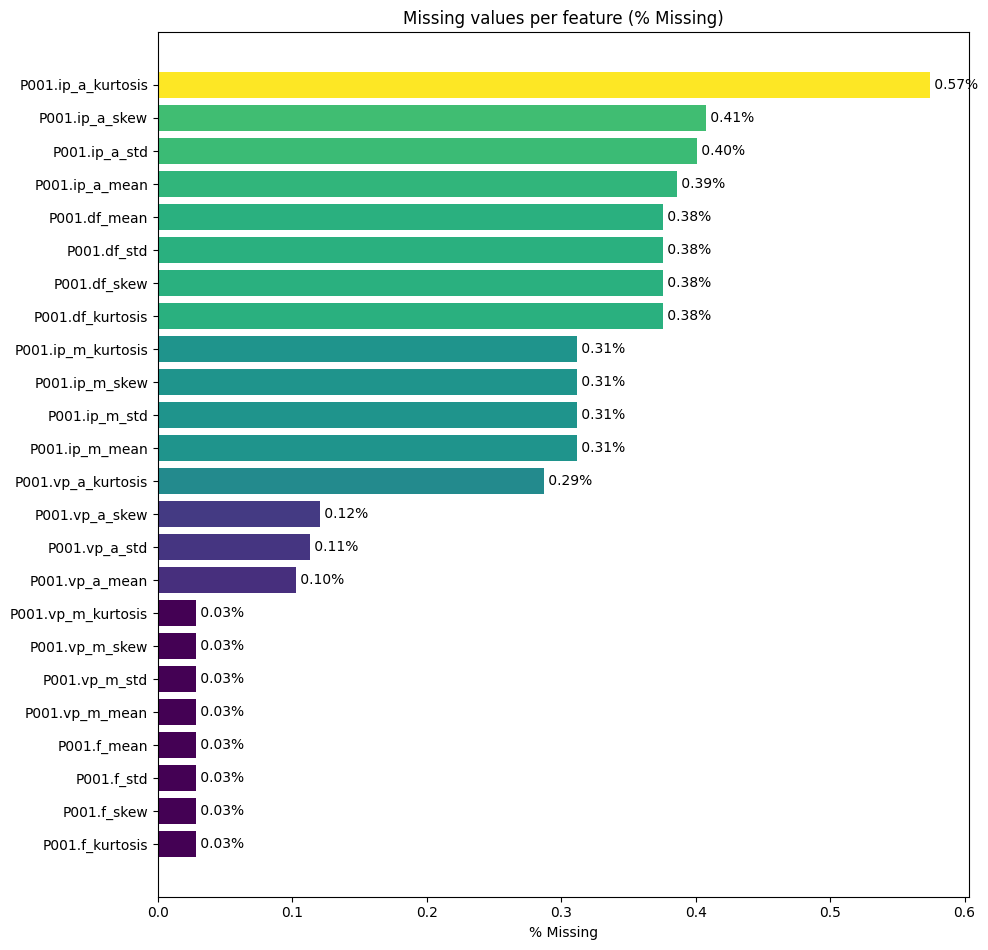


Saved wide missing matrix (X=missing, 0=present) to: missing_matrix_by_sigid.csv


feature,sigid,P001.df_mean,P001.df_std,P001.df_skew,P001.df_kurtosis,P001.f_mean,P001.f_std,P001.f_skew,P001.f_kurtosis,P001.ip_a_mean,P001.ip_a_std,P001.ip_a_skew,P001.ip_a_kurtosis,P001.ip_m_mean,P001.ip_m_std,P001.ip_m_skew,P001.ip_m_kurtosis,P001.vp_a_mean,P001.vp_a_std,P001.vp_a_skew,P001.vp_a_kurtosis,P001.vp_m_mean,P001.vp_m_std,P001.vp_m_skew,P001.vp_m_kurtosis
0,977,0,0,0,0,0,0,0,0,X,X,X,X,0,0,0,0,X,X,X,X,0,0,0,0
1,984,X,X,X,X,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,999,X,X,X,X,X,X,X,X,X,X,X,X,X,X,X,X,X,X,X,X,X,X,X,X
3,1003,0,0,0,0,0,0,0,0,0,0,0,X,0,0,0,0,0,0,0,X,0,0,0,0
4,1035,X,X,X,X,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
5,1062,X,X,X,X,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
6,1065,X,X,X,X,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
7,1087,X,X,X,X,X,X,X,X,X,X,X,X,X,X,X,X,X,X,X,X,X,X,X,X
8,1088,X,X,X,X,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
9,1127,X,X,X,X,X,X,X,X,X,X,X,X,X,X,X,X,X,X,X,X,X,X,X,X


In [ ]:
from IPython.display import display
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.cm import get_cmap
from matplotlib.colors import Normalize

def _plot_missing_percent(series, title):
    """
    Barh plot for % missing, pretty colors via a colormap.
    `series` should be a Series indexed by column name with values as % (0..100).
    """
    s = series[series > 0].sort_values(ascending=True)
    if s.empty:
        print(f"{title}: no missing values.")
        return
    # color map driven by % missing
    cmap = get_cmap('viridis')  # nice, modern gradient
    norm = Normalize(vmin=float(s.min()), vmax=float(s.max()))
    colors = cmap(norm(s.values))

    fig, ax = plt.subplots(figsize=(10, max(3, 0.40 * len(s))))
    ax.barh(s.index.astype(str), s.values, color=colors)
    ax.set_xlabel("% Missing")
    ax.set_title(title)

    # annotate % at end of bars
    for i, v in enumerate(s.values):
        ax.text(v, i, f" {v:.2f}%", va='center')

    plt.tight_layout()
    plt.show()

if 'df' in locals():
    print("Data Summary:")
    display(pd.DataFrame({"Metric": ["Total samples"], "Value": [len(df)]}))

    # Primary label distribution as a table
    if 'primary' in df.columns:
        primary_counts = df['primary'].value_counts(dropna=False).reset_index()
        primary_counts.columns = ['Primary Label', 'Count']
        print("\nPrimary label distribution:")
        display(primary_counts)

    # Secondary label count
    if 'secondary' in df.columns:
        sec_count_df = pd.DataFrame(
            {"Metric": ["Unique secondary labels"], "Value": [df['secondary'].nunique(dropna=True)]}
        )
        display(sec_count_df)

    # Tertiary label count
    if 'tertiary' in df.columns:
        tert_count_df = pd.DataFrame(
            {"Metric": ["Unique tertiary labels"], "Value": [df['tertiary'].nunique(dropna=True)]}
        )
        display(tert_count_df)

    # ---------- Missingness analysis ----------
    # Prefer 'sigid', then 'sig_id', then 'id'; else fall back to row index
    id_col = next((c for c in ['sigid', 'sig_id', 'id'] if c in df.columns), None)
    id_label = id_col if id_col else 'row_ix'  # label used in outputs

    exclude_cols = [c for c in ['primary', 'secondary', 'tertiary', id_col] if c in df.columns]
    feature_cols = [c for c in df.columns if c not in exclude_cols]

    # ----- Keep ONLY feature-level missingness -----
    if feature_cols:
        # counts & % missing for features
        feat_missing_counts = df[feature_cols].isna().sum()
        m_feat = (
            feat_missing_counts[feat_missing_counts > 0]
            .sort_values(ascending=False)
            .rename('Missing Values')
            .to_frame()
        )
        if not m_feat.empty:
            m_feat['% Missing'] = (m_feat['Missing Values'] / len(df) * 100).round(2)
            print("\nMissing values per *feature*:")
            display(m_feat)

            # (2) Plot % Missing with nice colors
            feat_missing_pct = (df[feature_cols].isna().mean() * 100)
            _plot_missing_percent(feat_missing_pct, "Missing values per feature (% Missing)")

            # Build tidy long of (sigid, feature) pairs that are missing
            miss_long = (
                df[feature_cols]
                .isna()
                .stack()
                .rename('is_missing')
                .reset_index()
            )
            miss_long = miss_long[miss_long['is_missing']]
            miss_long.rename(columns={'level_0': 'row_ix', 'level_1': 'feature'}, inplace=True)

            # Attach ID column values
            if id_col:
                miss_long[id_label] = df.loc[miss_long['row_ix'], id_col].values
            else:
                miss_long[id_label] = miss_long['row_ix']

            miss_long = miss_long[[id_label, 'feature']].sort_values(['feature', id_label]).reset_index(drop=True)

            # (3) Wide matrix CSV: 'X' for missing, '0' otherwise
            wide = (
                miss_long
                .assign(val='X')
                .pivot_table(index=id_label, columns='feature', values='val', aggfunc='first')
                .reindex(columns=feature_cols)  # keep original feature order
                .fillna('0')
            )
            wide.insert(0, id_label, wide.index)  # include ID as first col
            wide = wide.reset_index(drop=True)

            wide_csv_path = 'missing_matrix_by_sigid.csv'
            wide.to_csv(wide_csv_path, index=False)
            print(f"\nSaved wide missing matrix (X=missing, 0=present) to: {wide_csv_path}")
            display(wide.head(10))

            # (4) Feature → sigids table (display only; no CSV saved)
            ids_by_feature = (
                miss_long.groupby('feature')[id_label]
                .apply(lambda s: list(pd.unique(s)))
                .reset_index(name=f'{id_label}s_missing')
                .sort_values('feature')
            )
            #print("\nFor each feature, the sigids that are missing it (preview):")
            #display(ids_by_feature.head(20))
        else:
            print("\nNo missing values found among feature columns.")
    else:
        print("\nNo feature columns inferred (only labels/ID present).")

    # Note:
    # - Removed 'Missing values per column' table & figure entirely.
    # - Not writing 'sigids_missing_by_feature.csv' anymore as requested.


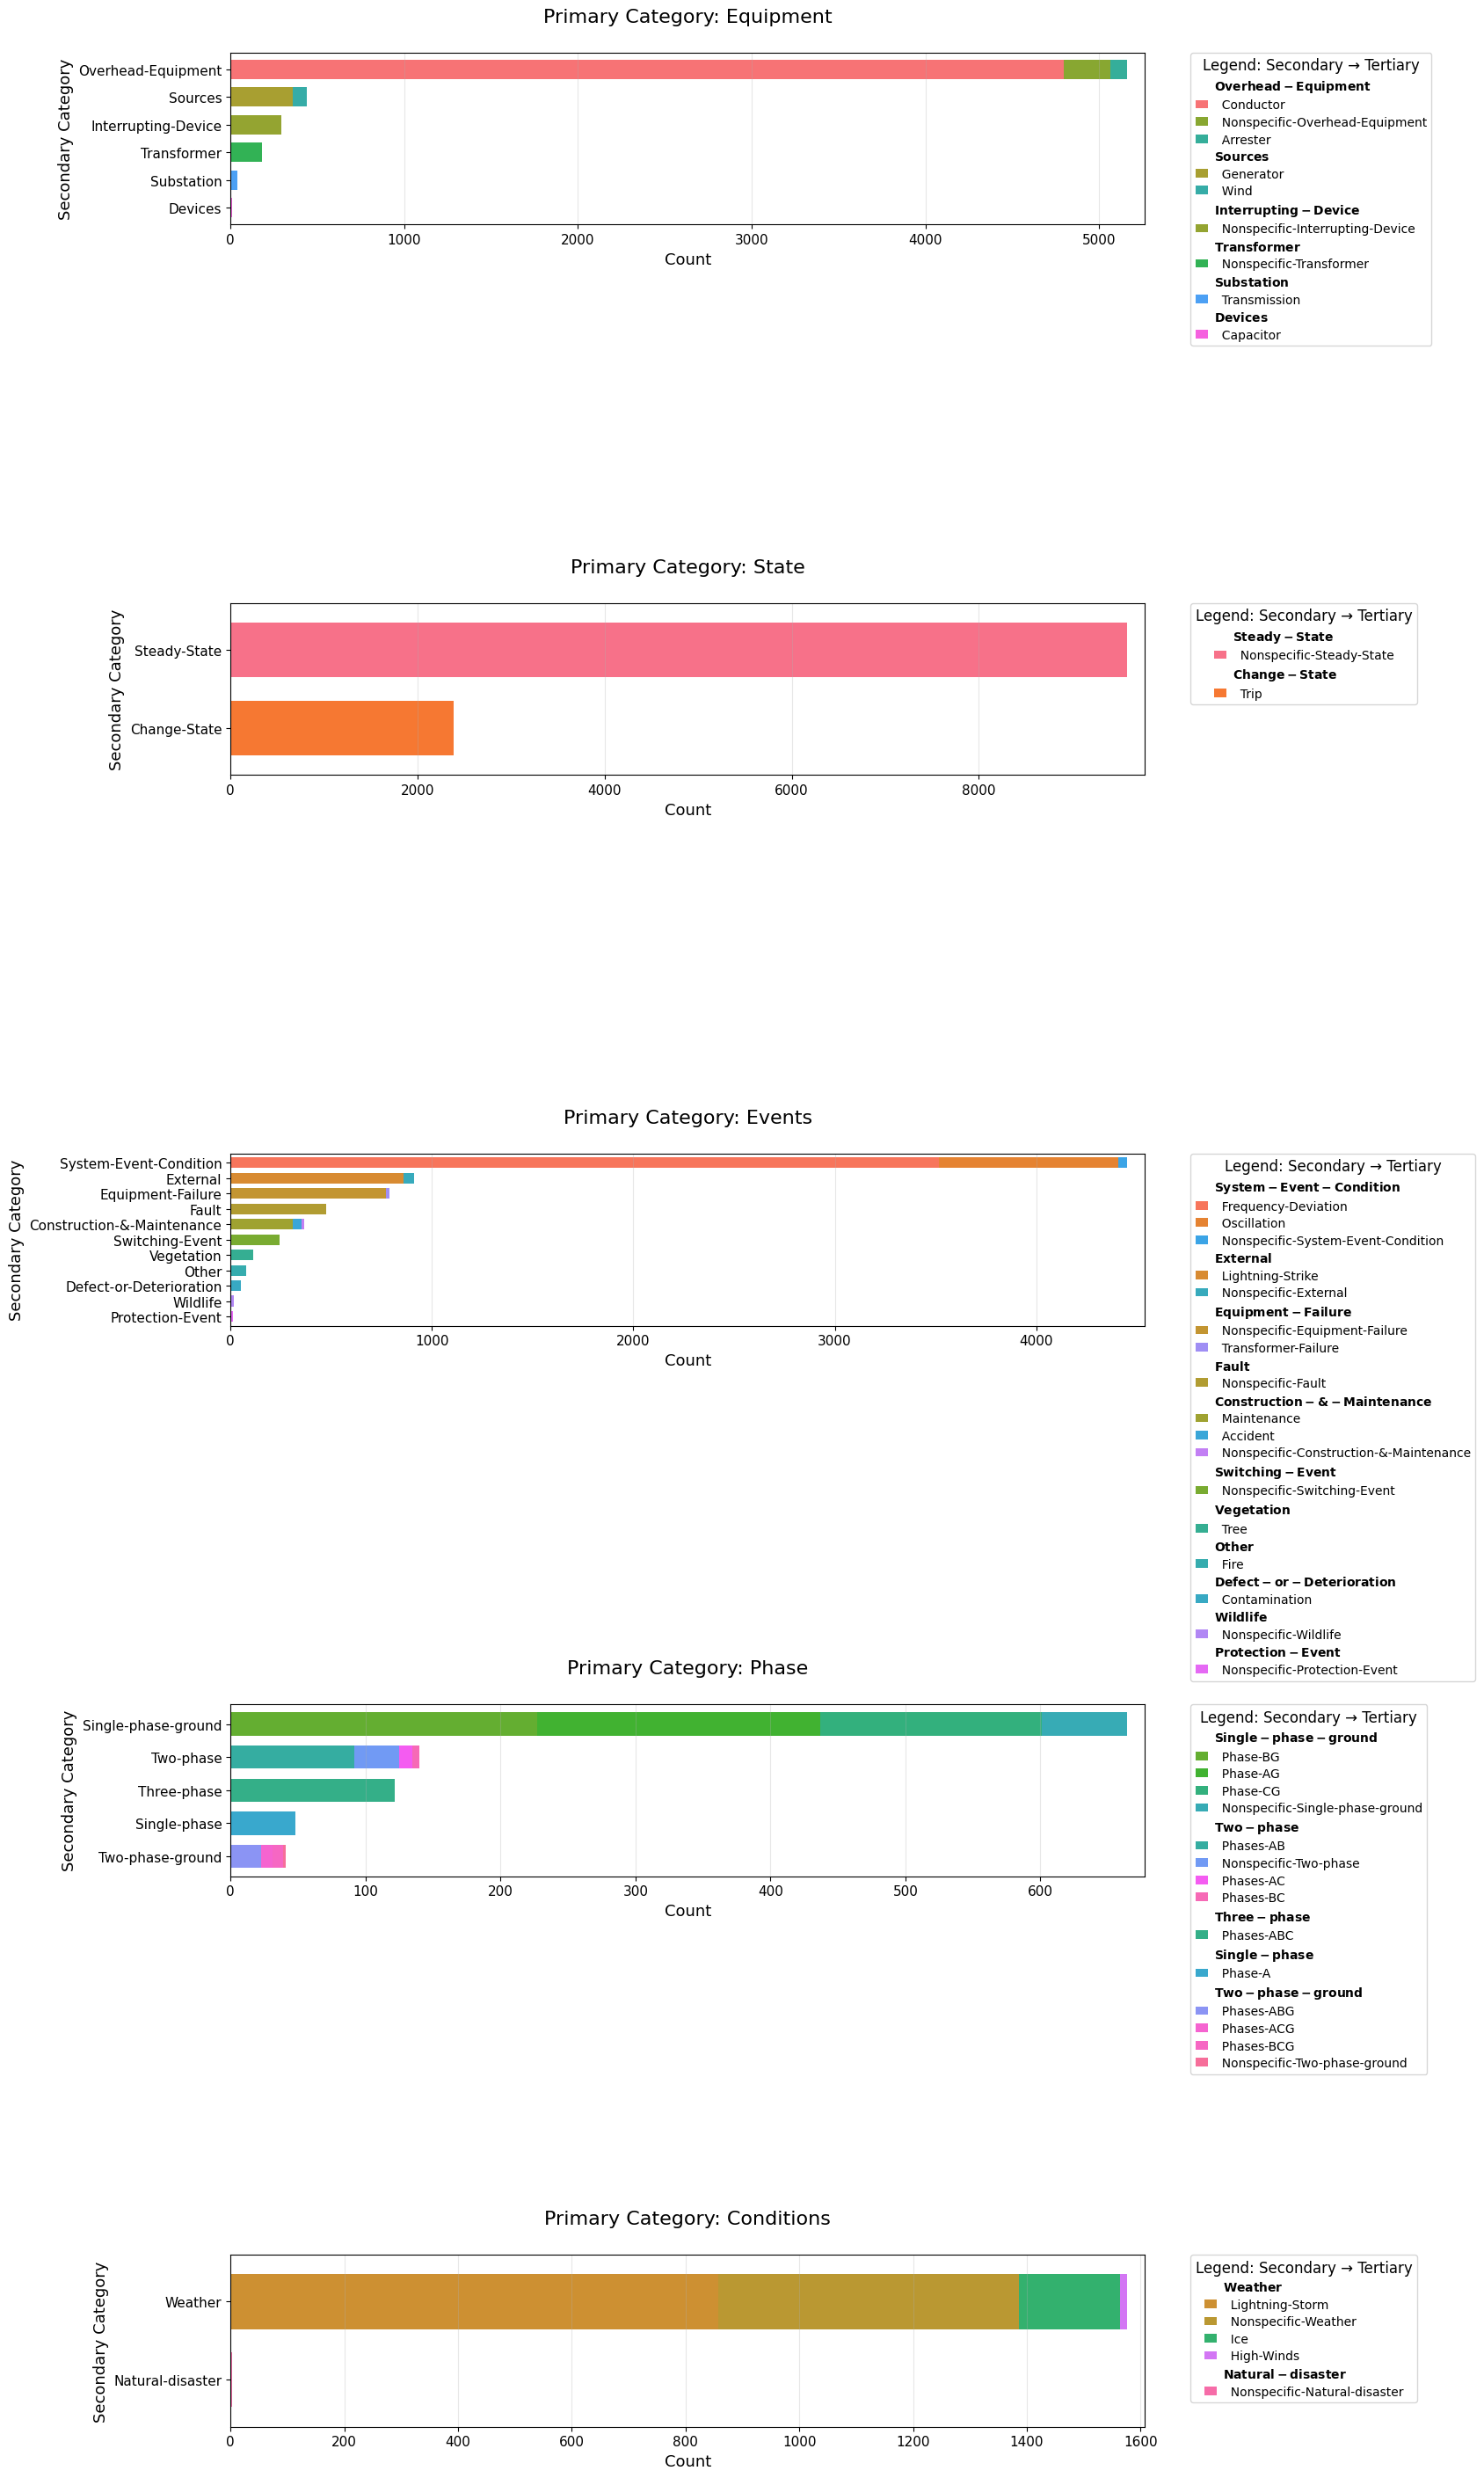

In [23]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# Assuming your data is in a DataFrame called 'df'
# First, get the grouped data
grouped_data = df.groupby(['primary', 'secondary', 'tertiary']).size().reset_index(name='count')

# Get unique primary categories
primary_categories = df['primary'].unique()

# Calculate total counts for each secondary category to sort by (global order)
secondary_totals = df.groupby('secondary').size().sort_values(ascending=False)
secondary_order = secondary_totals.index.tolist()

# Calculate total counts for each tertiary category to sort by (global order, highest first)
tertiary_totals = df.groupby('tertiary').size().sort_values(ascending=False)
tertiary_order = tertiary_totals.index.tolist()

# Color palette for tertiaries
colors = sns.color_palette("husl", n_colors=len(tertiary_order))
tertiary_colors = dict(zip(tertiary_order, colors))

# SOLUTION 1: Increase figure size and adjust spacing
# Make figure much wider and taller to accommodate content + legend
fig, axes = plt.subplots(
    nrows=len(primary_categories), 
    ncols=1, 
    figsize=(16, 6 * len(primary_categories))  # Increased from (12, 4 * len(...))
)

# Handle case where there's only one primary category
if len(primary_categories) == 1:
    axes = [axes]

for i, primary in enumerate(primary_categories):
    # Filter data for this primary category
    primary_data = grouped_data[grouped_data['primary'] == primary]
    
    # Pivot the data to create a matrix for stacking
    pivot_data = primary_data.pivot_table(
        index='secondary',
        columns='tertiary',
        values='count',
        fill_value=0
    )
    
    # Reorder secondary categories by global totals (keep only those present)
    available_secondary = [sec for sec in secondary_order if sec in pivot_data.index]
    pivot_data = pivot_data.reindex(available_secondary)
    
    # Reorder tertiary columns by global totals (keep only those present)
    available_tertiary = [tert for tert in tertiary_order if tert in pivot_data.columns]
    pivot_data = pivot_data[available_tertiary]
    
    # Horizontal stacked bar chart
    pivot_data.plot(
        kind='barh',
        stacked=True,
        ax=axes[i],
        color=[tertiary_colors[col] for col in pivot_data.columns],
        width=0.7,  # Slightly reduced bar thickness for cleaner look
        legend=False
    )
    
    # Axes cosmetics
    axes[i].set_title(f'Primary Category: {primary}', fontsize=16, pad=25)
    axes[i].set_xlabel('Count', fontsize=13)
    axes[i].set_ylabel('Secondary Category', fontsize=13)
    axes[i].tick_params(axis='y', rotation=0, labelsize=11)
    axes[i].tick_params(axis='x', labelsize=11)
    axes[i].invert_yaxis()  # largest totals at the top
    axes[i].margins(x=0.02)
    axes[i].grid(axis='x', alpha=0.3)  # Add subtle grid for readability

    # Build grouped legend: Secondary header -> its tertiaries
    legend_handles = []
    legend_labels = []

    for sec in available_secondary:
        row = pivot_data.loc[sec]
        # tertiaries present in this secondary (sorted by descending count within this secondary)
        present_terts = [t for t in available_tertiary if row.get(t, 0) > 0]
        if not present_terts:
            continue
        present_terts.sort(key=lambda t: row[t], reverse=True)

        # Secondary "subtitle" (bold text row; invisible handle)
        legend_handles.append(Line2D([0], [0], linestyle='none', marker=None))
        legend_labels.append(rf"$\bf{{{sec}}}$")  # bold via mathtext

        # Tertiary swatches under this secondary
        for t in present_terts:
            legend_handles.append(Patch(facecolor=tertiary_colors[t], edgecolor='none'))
            legend_labels.append(f"  {str(t)}")  # Indent tertiary items

    # SOLUTION 2: Better legend positioning and sizing
    axes[i].legend(
        legend_handles, legend_labels,
        title="Legend: Secondary → Tertiary",
        title_fontsize=12,
        fontsize=10,
        loc='upper left', 
        bbox_to_anchor=(1.05, 1.0),  # Move legend further right
        borderaxespad=0.0, 
        frameon=True, 
        ncol=1,
        labelspacing=0.4,  # Tighter spacing
        handlelength=1.0, 
        handletextpad=0.5
    )

# SOLUTION 3: Use constrained_layout instead of tight_layout + subplots_adjust
plt.subplots_adjust(
    left=0.1,      # Left margin
    right=0.75,    # Right margin (more space for legend)
    top=0.95,      # Top margin
    bottom=0.05,   # Bottom margin
    hspace=2.2     # Vertical space between subplots
)

plt.show()



## 5. Utility Functions

### 5.1 Class Rebalancing Function

Rebalance dataset using Gaussian Mixture Model to generate synthetic samples
for the minority class when imbalance is severe (minority < 33%).

In [ ]:
def rebalance(features, label):
    
    num_obs = len(label)
    label = label.values
    class0_weight = 1. - np.mean(label)
    class1_weight = np.mean(label)
    imbalance_ratio = class0_weight / class1_weight
    if class1_weight < 0.33:
        #########print('attempting rebalance')
        minority_class_indices = np.where(label)[0]
        # FILTER FEATURES TO THE MINORITY CLASS
        minority_class_features = features[minority_class_indices, :]
        # FIT FEATURES TO 1 COMPONENT GMM  (ASSUMING ALL EVENTS OF THE SAME TYPE IN SINGLE GAUSSIAN)
        gmm = GaussianMixture(n_components=1, random_state=0).fit(minority_class_features)
        # SAMPLE until at least 25% of MAJORITY CLASS
        num_needed_samples = int((0.33 * (num_obs*class0_weight)) - (num_obs * class1_weight))
        syn_samples = gmm.sample(n_samples=num_needed_samples)[0]
        features = np.vstack([features, syn_samples])
        label = np.hstack([np.array(label), np.ones(num_needed_samples)])
        class0_weight = 1. - np.mean(label)
        class1_weight = np.mean(label)
        imbalance_ratio = class0_weight / class1_weight
    # RETURN features, label, and  sum(negative instances) / sum(positive instances) as imbalance ratio
    # return imbalance_ratio
    return features, label, imbalance_ratio


def intersection(list_a, list_b):
    """
    Find intersection of two lists.
    """
    return [ elem for elem in list_a if elem in list_b ]

### 5.2 Model Training Function

Function to automatically train XGboosting binary classifiers for all Class (Secondary) and Sub-Class (Tertiary) labels under the Group label. This function will not return anything, but will automatically save pickled files of each binary classifier in the specified path. 
    
1. param df: The DataFrame that contains features, labels, and other identifying columns such as Signature ID.
2. param group_label: A string that defines which Group label to focus on.
3. n_estimators: The number of individual tree estimator used in voting for the RF classifier.
4. param max_depth: The max depth of tree voter in the RF classifier.
5. param path_to_save: A string to define path to save the pickled binary classifier for each Class (Secondary) and Sub-Class (Tertiary) label.

In [ ]:
def train_for_group(df: pd.DataFrame, group_label: str, n_estimators: int = 1000, max_depth: int = 8, path_to_save: str = 'Classifiers'):

    df1 = df.loc[df['primary'] == group_label].copy().dropna().reset_index()

    arr_class = np.asanyarray(df1.groupby(['secondary']).nunique().sort_values(by=['index'], ascending=False).index)
    arr_subclass = np.asanyarray(df1.groupby(['tertiary']).nunique().sort_values(by=['index'], ascending=False).index)

    if df1.shape[0] != 0:
        features = df1.iloc[:, -(df1.shape[1] - 5):].values
        # label = df1['secondary']
        # x_train, _, y_train, _ = train_test_split(features, label, test_size=0.05, random_state=42)

        for evttag in arr_class:
            ############print("Training classifier for {} Class label...\n".format(evttag))
            # Transform y_train such that it is a binary value w.r.t. each Class (Secondary) event tag. 
            # y_train_copy = y_train == evttag
            label = df1['secondary'] == evttag

            # Check balance of the y_train and rebalance if necessary
            features_reb, label_reb, imbalance_ratio = rebalance(features, label)
            x_train_reb, _, y_train_reb, _ = train_test_split(features_reb, label_reb, test_size=0.05, random_state=42)

            xgb_model = xgb.XGBClassifier(n_estimators=n_estimators, max_depth=max_depth, random_state=42, early_stopping_rounds=5)
            param_dist = {
                "subsample": stats.uniform(loc=0.5, scale=0.2),  
                "colsample_bytree": stats.uniform(loc=0.5, scale=0.2),
                'scale_pos_weight': stats.uniform(loc=imbalance_ratio, scale=1)  # set loc based on sum(negative instances) / sum(positive instances)
                }
            x_train_sub, x_val, y_train_sub, y_val = train_test_split(x_train_reb, y_train_reb, test_size=0.15)
            model = RandomizedSearchCV(xgb_model,
                                       param_distributions=param_dist,
                                       n_iter=100,
                                       cv=5,
                                       scoring='accuracy')

            model.fit(x_train_sub, y_train_sub, eval_set=[(x_val, y_val)], verbose=False)

            # Once training is done, pickle the binary classifier in the save path.
            with open('{}/{}_{}.pickle'.format(path_to_save, SAVE_PREFIX, evttag), 'wb') as handle:
                pickle.dump(model, handle, protocol=pickle.HIGHEST_PROTOCOL)

        # label = df1['tertiary']
        # x_train, _, y_train, _ = train_test_split(features, label, test_size=0.05, random_state=42)
        
        for evttag in arr_subclass:
            ########print("Training classifier for {} Sub-Class label...\n".format(evttag))
            # Transform y_train such that it is a binary value w.r.t. each Sub-Class (Tertiary) event tag.
            # y_train_copy = y_train == evttag
            label = df1['tertiary'] == evttag

           # Check balance of the y_train and rebalance if necessary
            features_reb, label_reb, imbalance_ratio = rebalance(features, label)
            x_train_reb, _, y_train_reb, _ = train_test_split(features_reb, label_reb, test_size=0.05, random_state=42)

            # model = RandomForestClassifier(n_estimators=n_estimators, max_depth=max_depth, random_state=42)
            # model.fit(x_train, y_train_copy.values)

            xgb_model = xgb.XGBClassifier(n_estimators=n_estimators, max_depth=max_depth, random_state=42, early_stopping_rounds=5)
            param_dist = {
                "subsample": stats.uniform(loc=0.5, scale=0.2),  
                "colsample_bytree": stats.uniform(loc=0.5, scale=0.2),
                'scale_pos_weight': stats.uniform(loc=imbalance_ratio, scale=1)  # set loc based on sum(negative instances) / sum(positive instances)
                }
            x_train_sub, x_val, y_train_sub, y_val = train_test_split(x_train_reb, y_train_reb, test_size=0.15)
            model = RandomizedSearchCV(xgb_model,
                                       param_distributions=param_dist,
                                       n_iter=100,
                                       cv=5,
                                       scoring='accuracy')

            model.fit(x_train_sub, y_train_sub, eval_set=[(x_val, y_val)], verbose=False)

            with open('{}/{}_{}.pickle'.format(path_to_save, SAVE_PREFIX, evttag), 'wb') as handle:
                pickle.dump(model, handle, protocol=pickle.HIGHEST_PROTOCOL)

### 5.3 Prediction Functions

Function that inputs the features of a single test sample to the binary classifiers associated with each label in the input label_list.

1. param test_features: The features for a single test sample.
2. param label_list: Each label in the label_list should have an associated binary classifier and test_features will be inputted to each of these binary classifiers. 
3. param path_to_read: Specifies the directory to find the pickled classifier. Right now, this assumes that the path_to_read is in the directory `Classifiers/Transmission_PMU` by default and that there is a file or files named `RF_{evttag}` where evttag is the event tag label. 
4. return: The predicted class after getting the maximum positive probabilities outputted by each binary classifier representing each label in label_list. 

In [ ]:
def successive_binary_classifier(test_features: pd.DataFrame, label_list: list, path_to_read: str = 'Classifiers') -> str:

    proba_temp = 0
    pred_label = ''
    probStatic = []
    for evttag in label_list:
        evttag_model_file = '{}/{}_{}.pickle'.format(path_to_read, SAVE_PREFIX, evttag)
        if not os.path.exists(evttag_model_file):
            continue
        with open(evttag_model_file, 'rb') as handle:
            rf = pickle.load(handle)
            proba = rf.predict_proba(test_features)
            if proba[0][1] > proba_temp:
                probStatic.append([evttag,proba[0][1]])
                proba_temp = proba[0][1]
                pred_label = evttag
    probStatic = np.array(probStatic)
    # Compare and select top three (or less) events that returne highest likelyhood  
    sorted_probas_indices = np.argsort(probStatic[:,1].astype(float))[::-1]
    sorted_probas = probStatic[sorted_probas_indices]
    if sorted_probas.shape[0] > 3:
        sorted_probas = sorted_probas[:3,:]
    # print (sorted_probas)
    return pred_label, probStatic

### 5.4 Validation Function

    
Function that runs all the signatures in the testing dataset in a way that is inherently hierarchical. In particular, this function will follow the local classifier per node (LCN) approach, assuming that the Class label that is first predicted is correct, i.e. the predicted Class label will be used to predict the Sub-Class label regardless of correctness of Class label.
    
1. param df: The DataFrame that contains features, labels, and other identifying columns such as Signature ID.
2. param group_label: A string that defines which Group label to focus on.
3. return: A DataFrame that contains all the actual versus predicted Class and Sub-Class.


In [ ]:
def validation(df: pd.DataFrame, group_label: str) -> tuple[pd.DataFrame, float, float, float, float]:

    df1 = df.loc[df['primary'] == group_label].copy().dropna().reset_index()

    arr_class = np.asanyarray(df1.groupby(['secondary']).nunique().sort_values(by=['index'], ascending=False).index)
    if df1.shape[0] != 0:
        features = df1.iloc[:, -(df1.shape[1] - 5):]
        label = df1['secondary']
        _, x_test, _, _ = train_test_split(features, label, test_size=0.05, random_state=42)

    sigid = []
    group = []
    actual_class = []
    actual_subclass = []
    pred_class = []
    pred_subclass = []

    for idx in x_test.index:
        print("Testing for Sig ID {}".format(df1.iloc[idx]["sigid"]))
        test_features = x_test[x_test.index == idx]
        sigid.append(df1.iloc[idx]['sigid'])
        group.append(group_label)
        actual_class.append(df1.iloc[idx]['secondary'])
        actual_subclass.append(df1.iloc[idx]['tertiary'])

        pred_class_1, static = successive_binary_classifier(test_features, arr_class)
        pred_class.append(pred_class_1)

        pred_subclass_1, static = successive_binary_classifier(test_features, sec_to_tert_dict[pred_class_1])
        pred_subclass.append(pred_subclass_1)
    
    group_results = pd.DataFrame(columns=['Sig_ID', 'Group', 'Actual_Class', 'Predicted_Class', 'Actual_Subclass', 'Predicted_Subclass'])
    group_results['Sig_ID'] = sigid
    group_results['Group'] = group
    group_results['Actual_Class'] = actual_class
    group_results['Predicted_Class'] = pred_class
    group_results['Actual_Subclass'] = actual_subclass
    group_results['Predicted_Subclass'] = pred_subclass

    correct_classification = group_results.loc[group_results['Actual_Subclass'] == group_results['Predicted_Subclass']].shape[0]
    acc = correct_classification / group_results.shape[0] * 100

    hP_num = 0
    hP_denom = 0
    hR_num = 0
    hR_denom = 0
    beta = 1

    for row in range(group_results.shape[0]):
        C_i = []
        C_i_hat = []
        C_i_prime = []
        C_i_prime_hat = []

        C_i.append(group_results['Actual_Subclass'][row])
        
        C_i_hat.append(group_results['Actual_Class'][row])
        C_i_hat.append(group_results['Actual_Subclass'][row])

        C_i_prime.append(group_results['Predicted_Subclass'][row])

        C_i_prime_hat.append(group_results['Predicted_Class'][row])
        C_i_prime_hat.append(group_results['Predicted_Subclass'][row])

        hP_num += len(intersection(C_i_hat, C_i_prime_hat))
        hP_denom += len(C_i_prime_hat)
        hR_num += len(intersection(C_i_hat, C_i_prime_hat))
        hR_denom += len(C_i_hat)

    hP = hP_num / hP_denom * 100
    hR = hR_num / hR_denom * 100
    hF = ((beta ** 2 + 1) * hP * hR) / (beta**2 * hP + hR)

    return group_results, acc, hP, hR, hF

## 6. Model Training Pipeline

This section trains all binary classifiers for each group. Training can be time-consuming depending on dataset size.

1. From a DataFrame with columns:
      ['Sig_ID', 'Group', 'Actual_Class', 'Predicted_Class',
       'Actual_Subclass', 'Predicted_Subclass']
2. compute, for each Actual_Class (secondary label):
      - Accuracy_sec
      - hP_sec, hR_sec, hF_sec

In [ ]:
def compute_secondary_metrics(group_results: pd.DataFrame) -> pd.DataFrame:

    rows = []
    beta = 1.0

    for sec_label in group_results['Actual_Class'].unique():
        df_sec = group_results[group_results['Actual_Class'] == sec_label]
        # 1) Accuracy on the secondary label
        acc_sec = (df_sec['Actual_Class'] == df_sec['Predicted_Class']).mean() * 100

        # 2) Hierarchical precision/recall on the two‐level path
        hP_num = hP_den = hR_num = hR_den = 0
        for _, row in df_sec.iterrows():
            actual_path    = [row['Actual_Class'],    row['Actual_Subclass']]
            predicted_path = [row['Predicted_Class'], row['Predicted_Subclass']]
            inter_len = len(set(actual_path) & set(predicted_path))

            hP_num += inter_len
            hP_den += len(predicted_path)
            hR_num += inter_len
            hR_den += len(actual_path)

        hP_sec = (hP_num / hP_den * 100) if hP_den > 0 else np.nan
        hR_sec = (hR_num / hR_den * 100) if hR_den > 0 else np.nan
        if (hP_sec + hR_sec) > 0:
            hF_sec = ((beta**2 + 1) * hP_sec * hR_sec) / (beta**2 * hP_sec + hR_sec)
        else:
            hF_sec = np.nan

        rows.append({
            'Group':        df_sec['Group'].iloc[0],
            'Secondary':    sec_label,
            'Accuracy_sec': acc_sec,
            'hP_sec':       hP_sec,
            'hR_sec':       hR_sec,
            'hF_sec':       hF_sec
        })

    return pd.DataFrame(rows)

## 7. Main Function

This section orchestrates end-to-end model training and testing across all Groups, saves per-row predictions and aggregate metrics, and (optionally) re-trains with explicit hyperparameters and timing.

### 7.1 Pipeline Functions (`compute_secondary_metrics`, `main`)

Defines the core orchestration:
- `compute_secondary_metrics(group_results)`: computes secondary-label metrics per `Actual_Class` (Accuracy, hierarchical Precision/Recall/F1 over the two-level path Class→Subclass).
- `main()`: optionally trains classifiers for each Group, runs validation across Groups, aggregates results, and writes:
  - per-row predictions: `Outputs/lcn_{SAVE_PREFIX}_test_results.csv`
  - primary (per-Group) metrics: `Outputs/lcn_{SAVE_PREFIX}_metrics_results.csv`
  - secondary (per-Class) metrics: `Outputs/lcn_{SAVE_PREFIX}_secondary_metrics_results.csv`


In [13]:
def main():
    """
    Main function that runs all training and testing automatically. 
    """
    # Train all binary classifiers in each Group (Primary) label.
    group_labels = ['Events', 'State', 'Equipment', 'Conditions', 'Phase']
    if flag_train_function:
        # rename_headers = [s.replace("P001.", "") for s in df.columns.tolist()]
        # df.columns = rename_headers
        for group_label in group_labels:
            train_for_group(df, group_label)

    acc = []
    hP = []
    hR = []
    hF = []

    print("Testing for {} Group label...\n".format(group_labels[0]))
    group_results, acc_group, hP_group, hR_group, hF_group = validation(df, group_labels[0])
    acc.append(acc_group)
    hP.append(hP_group)
    hR.append(hR_group)
    hF.append(hF_group)

    for group_label in group_labels:
        print("Testing for {} Group label...\n".format(group_label))
        if group_label != group_labels[0]:
            group_results_add, acc_group, hP_group, hR_group, hF_group = validation(df, group_label)
            acc.append(acc_group)
            hP.append(hP_group)
            hR.append(hR_group)
            hF.append(hF_group)
            
            group_results = pd.concat([group_results, group_results_add], ignore_index=True)

    # Maybe add a line here to save the group_results somewhere.
    print("Saving per Group label results...")
    group_results.to_csv('Outputs/lcn_{}_test_results.csv'.format(SAVE_PREFIX), index=False)

    metrics_results = pd.DataFrame(columns=['Group', 'Accuracy', 'hP', 'hR', 'hF'])
    metrics_results['Group'] = group_labels
    metrics_results['Accuracy'] = acc
    metrics_results['hP'] = hP
    metrics_results['hR'] = hR
    metrics_results['hF'] = hF

#Testing code------------------------------------------------------------------------------------------------
    print("Saving overall results...")
    #metrics_results.to_csv('Outputs/lcn_{}_metrics_results.csv'.format(SAVE_PREFIX), index=False)
    # Save primary‐level metrics
    metrics_results.to_csv(
        f'Outputs/lcn_{SAVE_PREFIX}_metrics_results.csv', index=False
    )
    print("Saved primary‐level metrics.")

    # ----------------------------------------------------------------
    # Now compute & save secondary‐level metrics
    sec_metrics_df = compute_secondary_metrics(group_results)
    sec_path = f'Outputs/lcn_{SAVE_PREFIX}_secondary_metrics_results.csv'
    sec_metrics_df.to_csv(sec_path, index=False)
    print(f"Saved secondary‐level metrics to {sec_path}")

### 7.2 Configure & Run the Pipeline
Loads inputs and kicks off `main()`:
- Reads features (`Inputs/pmu_transmission_features.csv`) into `df`
- Sets `SAVE_PREFIX` and loads `sec_to_tert_dict`
- Enables training with `flag_train_function = 1`
- Calls `main()` to train (if enabled), validate, and save outputs

In [14]:
# Re-training classifiers to match with latest version of sklearn started at 5/30 10:46am.
# Input a DataFrame that contains the statistical moments for all Providers 9 and 10 signatures, separated by sensor.
df = pd.read_csv('Inputs/pmu_transmission_features.csv')

SAVE_PREFIX = 'XGB_gs_es_rebalancE_scale_weights'

# Input a dictionary to map secondary labels to tertiary labels, to be used during hierarchical classification.
sec_to_tert_dict = json.load(open('Inputs/sec_to_tert_dict_transmission.json'))
flag_train_function = 1
main()

Training classifier for System-Event-Condition Class label...

Training classifier for External Class label...

attempting rebalance
Training classifier for Equipment-Failure Class label...

attempting rebalance
Training classifier for Fault Class label...

attempting rebalance
Training classifier for Construction-&-Maintenance Class label...

attempting rebalance
Training classifier for Switching-Event Class label...

attempting rebalance
Training classifier for Vegetation Class label...

attempting rebalance
Training classifier for Other Class label...

attempting rebalance
Training classifier for Defect-or-Deterioration Class label...

attempting rebalance
Training classifier for Wildlife Class label...

attempting rebalance
Training classifier for Protection-Event Class label...

attempting rebalance
Training classifier for Frequency-Deviation Sub-Class label...

Training classifier for Lightning-Strike Sub-Class label...

attempting rebalance
Training classifier for Oscillation Su

c:\Users\gandaramende1\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_split.py:805: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=5.
  warnings.warn(


Training classifier for Natural-disaster Class label...

attempting rebalance
Training classifier for Lightning-Storm Sub-Class label...

Training classifier for Nonspecific-Weather Sub-Class label...

Training classifier for Ice Sub-Class label...

attempting rebalance
Training classifier for High-Winds Sub-Class label...

attempting rebalance
Training classifier for Nonspecific-Natural-disaster Sub-Class label...

attempting rebalance
Training classifier for Single-phase-ground Class label...

Training classifier for Two-phase Class label...

attempting rebalance
Training classifier for Three-phase Class label...

attempting rebalance
Training classifier for Single-phase Class label...

attempting rebalance
Training classifier for Two-phase-ground Class label...

attempting rebalance
Training classifier for Phase-BG Sub-Class label...

attempting rebalance
Training classifier for Phase-AG Sub-Class label...

attempting rebalance
Training classifier for Phase-CG Sub-Class label...

at

In [15]:
# Train models for all groups (if enabled)
if 'df' in locals() and flag_train_function:
    print("Starting model training for all groups...")
    print("This may take a while depending on your dataset size.\n")
    
    training_times = {}
    import time
    
    for group_label in group_labels:
        start_time = time.time()
        
        try:
            train_for_group(df, group_label, n_estimators=N_ESTIMATORS, max_depth=MAX_DEPTH, path_to_save=CLASSIFIER_PATH)
            
            end_time = time.time()
            training_times[group_label] = end_time - start_time
            print(f"\nTraining time for {group_label}: {training_times[group_label]:.2f} seconds")
            
        except Exception as e:
            print(f"\nError training models for {group_label}: {str(e)}")
            continue
    
    print("\n" + "="*60)
    print("Training Summary:")
    for group, time_taken in training_times.items():
        print(f"  {group}: {time_taken:.2f} seconds")
    print(f"Total training time: {sum(training_times.values()):.2f} seconds")
    
elif not flag_train_function:
    print("Training is disabled. Set flag_train_function = 1 to enable training.")
else:
    print("Please load the data first.")

Starting model training for all groups...
This may take a while depending on your dataset size.

Training classifier for System-Event-Condition Class label...

Training classifier for External Class label...

attempting rebalance
Training classifier for Equipment-Failure Class label...

attempting rebalance
Training classifier for Fault Class label...

attempting rebalance
Training classifier for Construction-&-Maintenance Class label...

attempting rebalance
Training classifier for Switching-Event Class label...

attempting rebalance
Training classifier for Vegetation Class label...

attempting rebalance
Training classifier for Other Class label...

attempting rebalance
Training classifier for Defect-or-Deterioration Class label...

attempting rebalance
Training classifier for Wildlife Class label...

attempting rebalance
Training classifier for Protection-Event Class label...

attempting rebalance
Training classifier for Frequency-Deviation Sub-Class label...

Training classifier for

c:\Users\gandaramende1\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_split.py:805: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(
c:\Users\gandaramende1\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_validation.py:528: FitFailedWarning: 
100 fits failed out of a total of 500.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
100 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\gandaramende1\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)

Training classifier for Natural-disaster Class label...

attempting rebalance
Training classifier for Lightning-Storm Sub-Class label...

Training classifier for Nonspecific-Weather Sub-Class label...

Training classifier for Ice Sub-Class label...

attempting rebalance
Training classifier for High-Winds Sub-Class label...

attempting rebalance
Training classifier for Nonspecific-Natural-disaster Sub-Class label...

attempting rebalance

Training time for Conditions: 181.40 seconds
Training classifier for Single-phase-ground Class label...

Training classifier for Two-phase Class label...

attempting rebalance
Training classifier for Three-phase Class label...

attempting rebalance
Training classifier for Single-phase Class label...

attempting rebalance
Training classifier for Two-phase-ground Class label...

attempting rebalance
Training classifier for Phase-BG Sub-Class label...

attempting rebalance
Training classifier for Phase-AG Sub-Class label...

attempting rebalance
Training 

## 8. Model Validation and Testing

In [16]:
# Validate models for all groups
if 'df' in locals() and 'sec_to_tert_dict' in locals():
    print("Starting model validation...\n")
    
    acc = []
    hP = []
    hR = []
    hF = []
    all_group_results = None
    
    for i, group_label in enumerate(group_labels):
        try:
            print(f"\nTesting for {group_label} Group label...")
            group_results_add, acc_group, hP_group, hR_group, hF_group = validation(df, group_label)
            
            acc.append(acc_group)
            hP.append(hP_group)
            hR.append(hR_group)
            hF.append(hF_group)
            
            if all_group_results is None:
                all_group_results = group_results_add
            else:
                all_group_results = pd.concat([all_group_results, group_results_add], ignore_index=True)
                
        except Exception as e:
            print(f"Error validating {group_label}: {str(e)}")
            # Add None values for failed validations
            acc.append(None)
            hP.append(None)
            hR.append(None)
            hF.append(None)
            continue
    
    print("\n" + "="*60)
    print("Validation complete!")
else:
    print("Please ensure data and dictionaries are loaded.")

Starting model validation...


Testing for Events Group label...
Testing for Sig ID 2635
Testing for Sig ID 2232
Testing for Sig ID 1325
Testing for Sig ID 2107
Testing for Sig ID 2658
Testing for Sig ID 2135
Testing for Sig ID 2439
Testing for Sig ID 2217
Testing for Sig ID 2378
Testing for Sig ID 1644
Testing for Sig ID 1667
Testing for Sig ID 2197
Testing for Sig ID 2420
Testing for Sig ID 2026
Testing for Sig ID 2528
Testing for Sig ID 1045
Testing for Sig ID 2318
Testing for Sig ID 2404
Testing for Sig ID 2458
Testing for Sig ID 2440
Testing for Sig ID 2440
Testing for Sig ID 2084
Testing for Sig ID 1278
Testing for Sig ID 1967
Testing for Sig ID 1329
Testing for Sig ID 2044
Testing for Sig ID 1839
Testing for Sig ID 1527
Testing for Sig ID 2225
Testing for Sig ID 1585
Testing for Sig ID 2062
Testing for Sig ID 2031
Testing for Sig ID 1194
Testing for Sig ID 2222
Testing for Sig ID 2422
Testing for Sig ID 2376
Testing for Sig ID 2416
Testing for Sig ID 2080
Testing for Sig ID 2252

## 9. Results Analysis and Visualization

In [ ]:
# Create and display metrics summary
if 'acc' in locals() and len(acc) > 0:
    metrics_results = pd.DataFrame({
        'Group': group_labels,
        'Accuracy': acc,
        'hP': hP,
        'hR': hR,
        'hF': hF
    })
    
    print("\nOverall Performance Metrics:")
    ##### Round to three decimal points edit
    display(metrics_results.round(3))
    
    # Save metrics
    metrics_file = f'{OUTPUT_PATH}/lcn_{SAVE_PREFIX}_metrics_results.csv'
    metrics_results.to_csv(metrics_file, index=False)
    print(f"\nMetrics saved to: {metrics_file}")

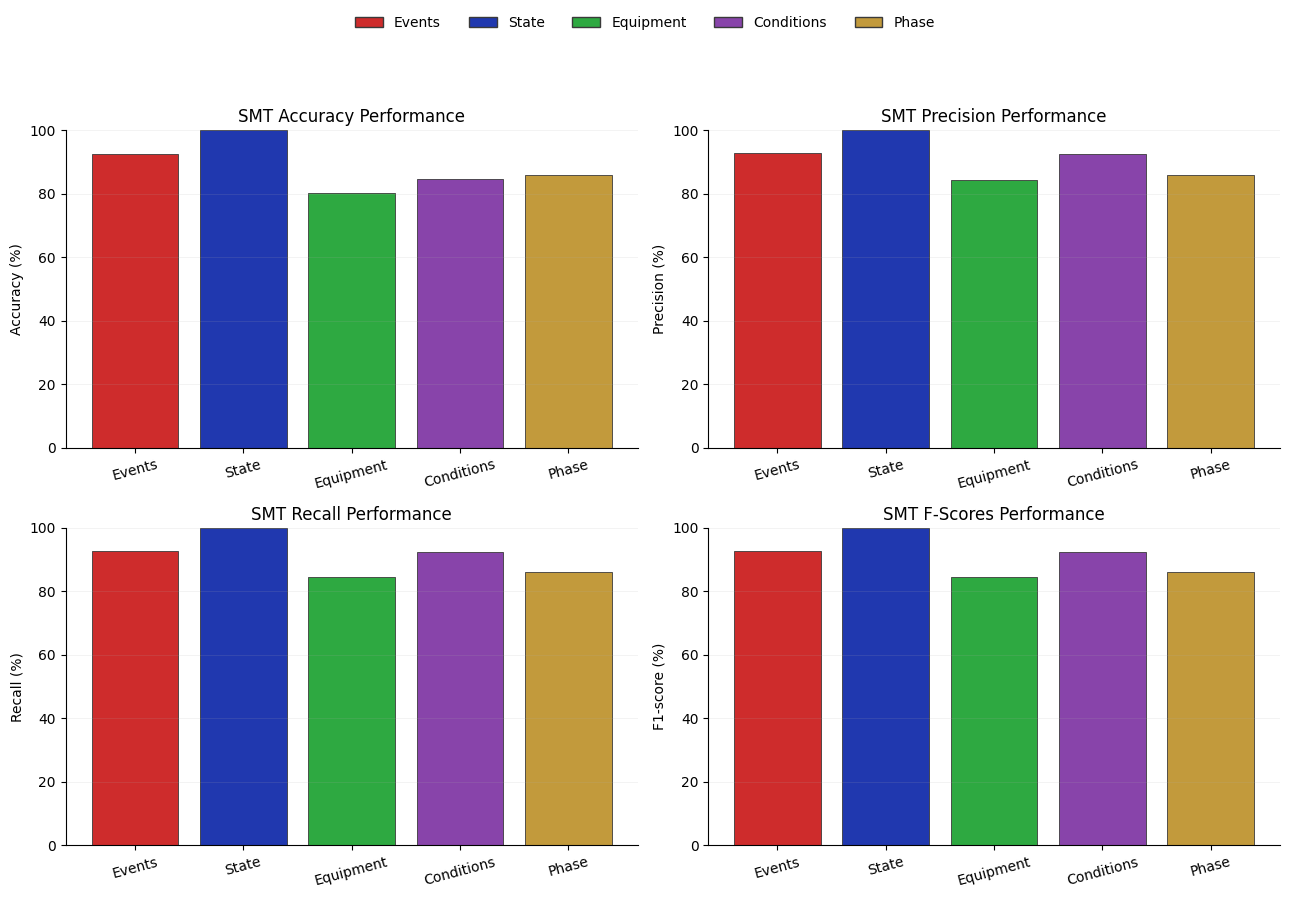

In [50]:
# Visualize metrics with elegant colors + legend outside
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

if 'metrics_results' in locals():
    # Paul Tol "Muted" palette (pleasant, professional)
    color_map = {
        'events':     "#CE2C2C",  # rose
        'state':      "#2038AF",  # blue
        'equipment':  "#2EA941",  # teal
        'conditions': "#8844AA",  # purple
        'phase':      "#C29A3C",  # sand/gold
    }
    neutral = '#8A8F98'   # fallback if a group name is unknown
    edge    = '#3A3A3A'

    group_norm = metrics_results['Group'].astype(str).str.lower().str.strip()
    bar_colors = [color_map.get(g, neutral) for g in group_norm]

    fig, axes = plt.subplots(2, 2, figsize=(13, 9))  # no constrained_layout
    panels = [
        ('SMT Accuracy Performance',  'Accuracy (%)',  metrics_results['Accuracy'], axes[0, 0]),
        ('SMT Precision Performance', 'Precision (%)', metrics_results['hP'],       axes[0, 1]),
        ('SMT Recall Performance',    'Recall (%)',    metrics_results['hR'],       axes[1, 0]),
        ('SMT F-Scores Performance',  'F1-score (%)',  metrics_results['hF'],       axes[1, 1]),
    ]

    for title, ylabel, series, ax in panels:
        ax.bar(metrics_results['Group'], series, color=bar_colors,
               edgecolor=edge, linewidth=0.6)
        ax.set_title(title)
        ax.set_ylabel(ylabel)
        ax.set_ylim(0, 100)
        ax.tick_params(axis='x', rotation=15)
        ax.grid(axis='y', linestyle='-', linewidth=0.4, alpha=0.25)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

    # Figure-level legend placed ABOVE the plots (won’t overlap axes)
    ordered = ['events','state','equipment','conditions','phase']
    handles = [
        Patch(facecolor=color_map[k], edgecolor=edge, label=k.title())
        for k in ordered if (group_norm == k).any()
    ]
    if handles:
        fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, 1.02),
                   ncol=len(handles), frameon=False)

    # Leave space at the top for the legend
    fig.tight_layout(rect=[0, 0.02, 1, 0.92])
    plt.show()


## 10. Model Inspection and Analysis

Examine individual models and their performance.

In [38]:
# Final summary
print("Pipeline Summary:")
print(f"- Model prefix: {SAVE_PREFIX}")
print(f"- Models trained: {len(model_files) if 'model_files' in locals() else 'Unknown'}")
print(f"- Output directory: {OUTPUT_PATH}")
print(f"- Classifier directory: {CLASSIFIER_PATH}")

if 'metrics_results' in locals():
    print(f"\nAverage performance across all groups:")
    print(f"- Accuracy: {metrics_results['Accuracy'].mean():.2f}%")
    print(f"- Hierarchical F-score: {metrics_results['hF'].mean():.2f}%")

Pipeline Summary:
- Model prefix: XGB_gs_es_rebalancE_scale_weights
- Models trained: 73
- Output directory: Outputs
- Classifier directory: Classifiers

Average performance across all groups:
- Accuracy: 88.70%
- Hierarchical F-score: 91.10%
